# Coordinated multi-item solver planning

Generate a three-item dataset, fit forecasts/scenarios on history, inspect the
integer plan, simulate held-out demand, then plot items and total missed sales.
Install `pip install -e ".[solver]"` first (SciPy with HiGHS; no commercial license).
Every plot below is stored in this notebook for viewing on GitHub.


In [1]:
from pathlib import Path
from dataclasses import replace, asdict
import math, random, statistics, sys, time
ROOT = Path.cwd() if (Path.cwd()/"src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT/"src"))
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
from replenishment import (
    InventoryState, ConstantOrderPolicy, RiskObjective, SolverItemConfig, SolverOptions,
    SharedResourceLimits, DeterministicRollingHorizonPolicy, ScenarioRollingHorizonPolicy,
    plan_replenishment, simulate_coordinated_replenishment,
    generate_standard_simulation_rows, split_standard_simulation_rows,
    standard_simulation_rows_to_dataframe, build_article_configs_from_standard_rows,
    simulate_replenishment_for_articles, optimize_policy_candidates,
    build_replenishment_decisions_from_simulations, replenishment_decision_rows_to_dataframe,
    plot_replenishment_decisions,
)
plt.switch_backend("agg")
pd.set_option("display.max_columns", None)
PLOT_DIR = ROOT/"docs"/"plots"
PLOT_DIR.mkdir(exist_ok=True)
seed = 17
periods = 72
training_end = 48
H = 5
options = SolverOptions(time_limit=30, mip_rel_gap=0)


In [2]:
METHOD='coordinated_solver'
TITLE='Coordinated multi-item solver planning'


## 1. Generate and inspect standard data


In [3]:
rows = generate_standard_simulation_rows(n_unique_ids=3, periods=periods,
    start_date="2026-01-01", frequency_days=1, forecast_start_period=training_end,
    history_mean=5, history_std=2, forecast_mean=5, forecast_std=1,
    lead_time=2, initial_on_hand=12, current_stock=12,
    holding_cost_per_unit=.4, stockout_cost_per_unit=8, order_cost_per_order=.6, seed=seed)
item_info = pd.DataFrame([
    dict(unique_id="A", item="Seasonal item", lead_time=2, review_period=1, cap=12, penalty=12),
    dict(unique_id="B", item="Intermittent spare", lead_time=3, review_period=2, cap=8, penalty=8),
    dict(unique_id="C", item="Rising demand", lead_time=0, review_period=1, cap=12, penalty=6),
])
item_parameters = item_info.set_index("unique_id").to_dict("index")
date_to_period = {ds:k for k,ds in enumerate(sorted({r.ds for r in rows}))}
rng = random.Random(seed+404)
prepared = []
for row in rows:
    t = date_to_period[row.ds]
    actual = int(row.actuals) if row.actuals is not None else max(0,round(rng.gauss(5,2)))
    if row.unique_id == "A":
        actual += [0,1,3,1,0,0,2,2][t%8]
    elif row.unique_id == "B":
        actual = rng.choices([0,4,8], weights=[.75,.125,.125])[0]
    else:
        actual += t//16
    item = item_parameters[row.unique_id]
    prepared.append(replace(row, demand=actual, actuals=actual, lead_time=item["lead_time"],
        stockout_cost_per_unit=item["penalty"]))
rows = prepared
backtest_rows, forecast_rows = split_standard_simulation_rows(rows)
def group_rows(values):
    return {uid:sorted([r for r in values if r.unique_id == uid],key=lambda r:r.ds)
            for uid in sorted({r.unique_id for r in values})}
train_by_article = group_rows(backtest_rows)
eval_by_article = group_rows(forecast_rows)
assert max(r.ds for r in backtest_rows) < min(r.ds for r in forecast_rows)
display(item_info)
display(standard_simulation_rows_to_dataframe(rows,library="pandas",include_demand=True).head(9))


,unique_id,item,lead_time,review_period,cap,penalty
0,A,Seasonal item,2,1,12,12
1,B,Intermittent spare,3,2,8,8
2,C,Rising demand,0,1,12,6


,unique_id,ds,demand,forecast,actuals,holding_cost_per_unit,stockout_cost_per_unit,order_cost_per_order,lead_time,initial_on_hand,current_stock,is_forecast,forecast_p50,forecast_p90
0,A,2026-01-01,5,3,5,0.4,12,0.6,2,12,12,False,3,4
1,A,2026-01-02,6,6,6,0.4,12,0.6,2,12,12,False,6,8
2,A,2026-01-03,5,5,5,0.4,12,0.6,2,12,12,False,5,6
3,A,2026-01-04,5,5,5,0.4,12,0.6,2,12,12,False,5,6
4,A,2026-01-05,5,6,5,0.4,12,0.6,2,12,12,False,6,8
5,A,2026-01-06,3,5,3,0.4,12,0.6,2,12,12,False,5,6
6,A,2026-01-07,7,4,7,0.4,12,0.6,2,12,12,False,4,5
7,A,2026-01-08,3,6,3,0.4,12,0.6,2,12,12,False,6,8
8,A,2026-01-09,9,2,9,0.4,12,0.6,2,12,12,False,2,2


## 2. Chronological fit

The first 48 dates are training; the last 24 are held out. Forecast models and
residual blocks use training demand only. Six joint residual paths share block
indices across articles, preserving historical cross-item dependence. Future
paths are forecasts, not future actuals. Integer forecasts are rounded explicitly.


In [4]:
# Fit only historical true demand. No evaluation actuals enter these models.
models = {}
training_residuals = {}
for uid, series in train_by_article.items():
    ys = [r.demand for r in series]
    mean = statistics.fmean(ys)
    if uid == "C":
        center = (len(ys)-1)/2
        slope = sum((t-center)*(y-mean) for t,y in enumerate(ys))/sum((t-center)**2 for t in range(len(ys)))
        intercept = mean-slope*center
        models[uid] = dict(kind="trend",intercept=intercept,slope=slope)
    else:
        models[uid] = dict(kind="seasonal",phase_means=tuple(
            statistics.fmean(ys[p::8]) for p in range(8)))

def forecast_at(uid, absolute_period):
    model = models[uid]
    if model["kind"] == "trend":
        value = model["intercept"]+model["slope"]*absolute_period
    else:
        value = model["phase_means"][absolute_period%8]
    return max(0,round(value))

for uid,series in train_by_article.items():
    training_residuals[uid] = tuple(r.demand-forecast_at(uid,t) for t,r in enumerate(series))

def forecast_vector(uid, evaluation_period):
    # The next demand is period t+1, since decisions follow current demand.
    return tuple(forecast_at(uid,training_end+evaluation_period+k) for k in range(1,H+1))

# Shared historical block indices preserve cross-item residual dependence.
# Six equal-weight paths; alpha=.5 leaves three observations in the CVaR tail.
starts = random.Random(seed+55).sample(range(training_end-H+1),6)
def joint_scenarios(evaluation_period):
    return {uid:tuple(tuple(max(0, forecast_vector(uid,evaluation_period)[k]
                     + training_residuals[uid][start+k]) for k in range(H))
                     for start in starts) for uid in train_by_article}

def joint_provider(states):
    return joint_scenarios(next(iter(states.values())).period)

def deterministic_provider(states):
    t = next(iter(states.values())).period
    return {uid:(forecast_vector(uid,t),) for uid in states}

items = {uid:SolverItemConfig(info["lead_time"], info["cap"],
    holding_cost_per_unit=.4,stockout_cost_per_unit=info["penalty"],
    order_cost_per_order=.6,order_cost_per_unit=.3,review_period=info["review_period"],
    min_order_quantity=2,pack_size=2) for uid,info in item_parameters.items()}
# Replace display forecasts with the training-only fitted forecasts as well.
rows = [replace(r,forecast=forecast_at(r.unique_id,date_to_period[r.ds]),
    forecast_percentiles={"p50":forecast_at(r.unique_id,date_to_period[r.ds])}) for r in rows]
backtest_rows,forecast_rows = split_standard_simulation_rows(rows)
eval_by_article = group_rows(forecast_rows)
df = standard_simulation_rows_to_dataframe(rows,library="pandas",include_demand=True)
assert df.actuals.eq(df.demand).all()
display(pd.DataFrame([dict(unique_id=uid,training_rows=len(train_by_article[uid]),
    fitted_model=models[uid],**asdict(item)) for uid,item in items.items()]))


,unique_id,training_rows,fitted_model,lead_time,max_order_quantity,holding_cost_per_unit,stockout_cost_per_unit,order_cost_per_order,order_cost_per_unit,review_period,min_order_quantity,pack_size
0,A,48,"{'kind': 'seasonal', 'phase_means': (5.6666666...",2,12,0.4,12.0,0.6,0.3,1,2,2
1,B,48,"{'kind': 'seasonal', 'phase_means': (1.3333333...",3,8,0.4,8.0,0.6,0.3,2,2,2
2,C,48,"{'kind': 'trend', 'intercept': 4.8307823129251...",0,12,0.4,6.0,0.6,0.3,1,2,2


## 3. Inspect the policy and its plan

Decisions follow demand; forecast column 1 therefore means next-period demand.
Future orders agree until the observed demand histories diverge. This is a
finite empirical scenario tree: a distinctive observation may reveal a whole
sampled path, so it does not represent arbitrary future uncertainty. Plans use
five future demand events, zero terminal value, no salvage or fulfillment beyond
that horizon, and disable orders that cannot serve modeled demand. Current
holding cost is sunk except for additional immediate stock. Configured costs
include fixed charges, packs of two and finite caps. Initial stock is 12 per item;
cold start, no warmup, no initial pipeline.


In [5]:
objective = RiskObjective("mean_cvar",alpha=.5,risk_weight=.5)
if METHOD == "deterministic_rolling_horizon":
    selected_policies = {uid:DeterministicRollingHorizonPolicy(item,
        lambda state,uid=uid:forecast_vector(uid,state.period),horizon=H,options=options)
        for uid,item in items.items()}
else:
    selected_policies = {uid:ScenarioRollingHorizonPolicy(item,
        lambda state,uid=uid:joint_scenarios(state.period)[uid],horizon=H,
        objective=objective,options=options) for uid,item in items.items()}

probe_states = {uid:InventoryState(0,max(0,series[0].current_stock-series[0].demand),0,0)
                for uid,series in eval_by_article.items()}
if METHOD == "coordinated_solver":
    limits = SharedResourceLimits(max_order_units=16,procurement_budget=6.6,max_receiving_units=16)
    inspected_plan = plan_replenishment(states=probe_states,items=items,
        demand_scenarios=joint_scenarios(0),limits=limits,objective=objective,options=options)
    inspected_id = "A"
else:
    limits = SharedResourceLimits()
    inspected_id = "item"
    inspected_plan = selected_policies["A"].plan(probe_states["A"])
display(pd.DataFrame([dict(status=inspected_plan.status,horizon=inspected_plan.horizon,
    terminal_value=inspected_plan.terminal_value,objective=inspected_plan.objective_value,
    objective_mode=inspected_plan.objective.mode,alpha=inspected_plan.objective.alpha,
    mean_cost=inspected_plan.mean_cost,cvar_cost=inspected_plan.cvar_cost,worst_cost=inspected_plan.worst_cost,
    gap=inspected_plan.mip_gap,dual_bound=inspected_plan.dual_bound,
    solve_seconds=inspected_plan.solve_seconds,first_orders=dict(inspected_plan.first_orders))]))
display(pd.DataFrame([dict(scenario=s,orders=orders,
    ending_stock=inspected_plan.inventories[inspected_id][s],
    lost_sales=inspected_plan.lost_sales[inspected_id][s],cost=inspected_plan.scenario_costs[s])
    for s,orders in enumerate(inspected_plan.orders[inspected_id])]))
assert len({orders[0] for orders in inspected_plan.orders[inspected_id]}) == 1


,status,horizon,terminal_value,objective,objective_mode,alpha,mean_cost,cvar_cost,worst_cost,gap,dual_bound,solve_seconds,first_orders
0,optimal,5,0.0,69.866667,mean_cvar,0.5,65.8,73.933333,88.2,0.0,69.866667,0.039879,"{'A': 8, 'B': 0, 'C': 8}"


,scenario,orders,ending_stock,lost_sales,cost
0,0,"(8, 2, 2, 8, 0)","(3, 6, 0, 1, 0)","(0, 0, 0, 0, 0)",59.4
1,1,"(8, 6, 4, 6, 0)","(2, 3, 1, 1, 0)","(0, 0, 0, 0, 0)",54.6
2,2,"(8, 0, 4, 8, 0)","(6, 6, 1, 0, 0)","(0, 0, 0, 0, 0)",59.6
3,3,"(8, 4, 6, 8, 0)","(0, 1, 1, 2, 1)","(0, 0, 0, 0, 0)",59.0
4,4,"(8, 6, 6, 8, 0)","(1, 0, 1, 0, 1)","(0, 1, 0, 0, 0)",88.2
5,5,"(8, 4, 4, 8, 0)","(4, 7, 4, 0, 0)","(0, 0, 0, 0, 0)",74.0


## 4. Simulate held-out demand and compare outcomes


In [6]:
def configs_for(policies, source_rows=forecast_rows):
    configs = build_article_configs_from_standard_rows(source_rows,policies=policies)
    return {uid:replace(c,order_cost_per_unit=.3) for uid,c in configs.items()}

eval_configs = configs_for(selected_policies)
started = time.perf_counter()
if METHOD == "coordinated_solver":
    coordinated = simulate_coordinated_replenishment(articles=eval_configs,
        demand_scenarios=joint_provider,limits=limits,objective=objective,options=options)
    eval_simulations = coordinated.simulations
    # The deterministic baseline obeys the SAME shared and operational constraints.
    baseline_simulations = simulate_coordinated_replenishment(articles=eval_configs,
        demand_scenarios=deterministic_provider,limits=limits,options=options).simulations
    baseline_name = "Deterministic joint planner (same limits)"
else:
    eval_simulations = simulate_replenishment_for_articles(eval_configs)
    baseline_policies = {}
    for uid,series in train_by_article.items():
        item = items[uid]
        # Constant orders respect MOQ, case packs, caps and review cadence.
        candidates = {str(q):ConstantOrderPolicy(q,item.review_period)
            for q in range(0,item.max_order_quantity+1,item.pack_size)}
        fit = optimize_policy_candidates(candidates=candidates,periods=len(series),
            demand=[r.demand for r in series],initial_on_hand=series[0].initial_on_hand,
            lead_time=item.lead_time,holding_cost_per_unit=item.holding_cost_per_unit,
            stockout_cost_per_unit=item.stockout_cost_per_unit,
            order_cost_per_order=item.order_cost_per_order,order_cost_per_unit=item.order_cost_per_unit)
        baseline_policies[uid] = fit.policy
    baseline_simulations = simulate_replenishment_for_articles(configs_for(baseline_policies))
    baseline_name = "Training-tuned constant orders"
runtime = time.perf_counter()-started
records = []
for label,simulations in [(TITLE,eval_simulations),(baseline_name,baseline_simulations)]:
    for uid,result in simulations.items():
        summary = result.summary
        records.append(dict(method=label,unique_id=uid,total_cost=summary.total_cost,
            demand=summary.total_demand,missed_units=summary.total_lost_sales,
            fill_rate=summary.fill_rate,average_stock=summary.average_on_hand,
            peak_stock=max(s.ending_on_hand for s in result.snapshots),
            order_count=sum(s.order_placed>0 for s in result.snapshots)))
print(f"Evaluation and baseline runtime: {runtime:.3f} seconds")
display(pd.DataFrame(records).round(4))
comparison = pd.DataFrame(records).groupby("method",as_index=False)[["total_cost","demand","missed_units"]].sum()
comparison["fill_rate"] = 1-comparison.missed_units/comparison.demand
display(comparison.round(4))
example_id = "A"


Evaluation and baseline runtime: 2.501 seconds


,method,unique_id,total_cost,demand,missed_units,fill_rate,average_stock,peak_stock,order_count
0,Coordinated multi-item solver planning,A,138.2,144,3,0.9792,4.5833,10,24
1,Coordinated multi-item solver planning,B,143.4,40,12,0.7000,4.0000,12,6
2,Coordinated multi-item solver planning,C,236.6,206,12,0.9417,9.7083,12,24
3,Deterministic joint planner (same limits),A,221.4,144,12,0.9167,2.3750,9,24
4,Deterministic joint planner (same limits),B,172.0,40,16,0.6000,3.8333,12,5
5,Deterministic joint planner (same limits),C,275.6,206,20,0.9029,8.9583,13,24


,method,total_cost,demand,missed_units,fill_rate
0,Coordinated multi-item solver planning,518.2,390,27,0.9308
1,Deterministic joint planner (same limits),669.0,390,48,0.8769


## 5. Inspect executed decisions

Actual plotted demand and simulated demand are the same realization. These
assertions reconcile every item's starting stock, ending stock and missed sales.


In [7]:
decision_rows=build_replenishment_decisions_from_simulations(forecast_rows,eval_simulations)
decision_df=replenishment_decision_rows_to_dataframe(decision_rows,library="pandas")
assert len(decision_df)==len(forecast_rows)
assert int(decision_df.missed_sales.sum())==sum(r.summary.total_lost_sales for r in eval_simulations.values())
for uid,result in eval_simulations.items():
    article_decisions=decision_df[decision_df.unique_id==uid].sort_values("ds")
    assert article_decisions.missed_sales.tolist()==[s.lost_sales for s in result.snapshots]
    assert article_decisions.ending_stock.tolist()==[s.ending_on_hand for s in result.snapshots]
    assert article_decisions.starting_stock.tolist()==[s.starting_on_hand for s in result.snapshots]
    assert article_decisions.demand.tolist()==[row.demand for row in eval_by_article[uid]]
columns=["unique_id","ds","demand","quantity","incoming_stock","starting_stock",
         "ending_stock","on_order","missed_sales","reorder_point","order_up_to"]
display(decision_df.loc[decision_df.unique_id==example_id,columns].head(16))


,unique_id,ds,demand,quantity,incoming_stock,starting_stock,ending_stock,on_order,missed_sales,reorder_point,order_up_to
0,A,2026-02-18,3,8,0,12,9,8,0,None,None
1,A,2026-02-19,4,6,0,9,5,14,0,None,None
2,A,2026-02-20,10,8,8,13,3,14,0,None,None
3,A,2026-02-21,4,2,6,9,5,10,0,None,None
4,A,2026-02-22,3,4,8,13,10,6,0,None,None
5,A,2026-02-23,5,6,2,12,7,10,0,None,None
6,A,2026-02-24,8,6,4,11,3,12,0,None,None
7,A,2026-02-25,5,6,6,9,4,12,0,None,None
8,A,2026-02-26,3,4,6,10,7,10,0,None,None
9,A,2026-02-27,5,8,6,13,8,12,0,None,None


## 6. Example items: demand, stock and missed sales


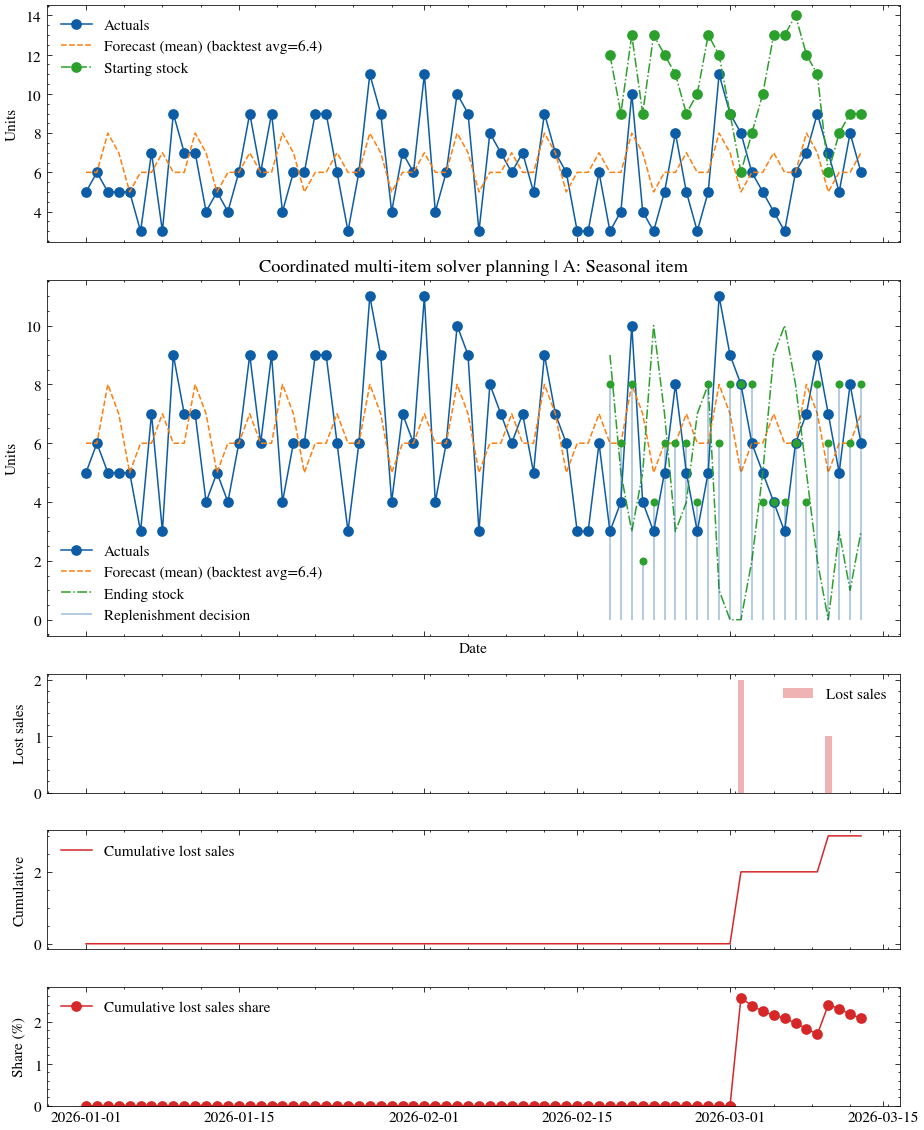

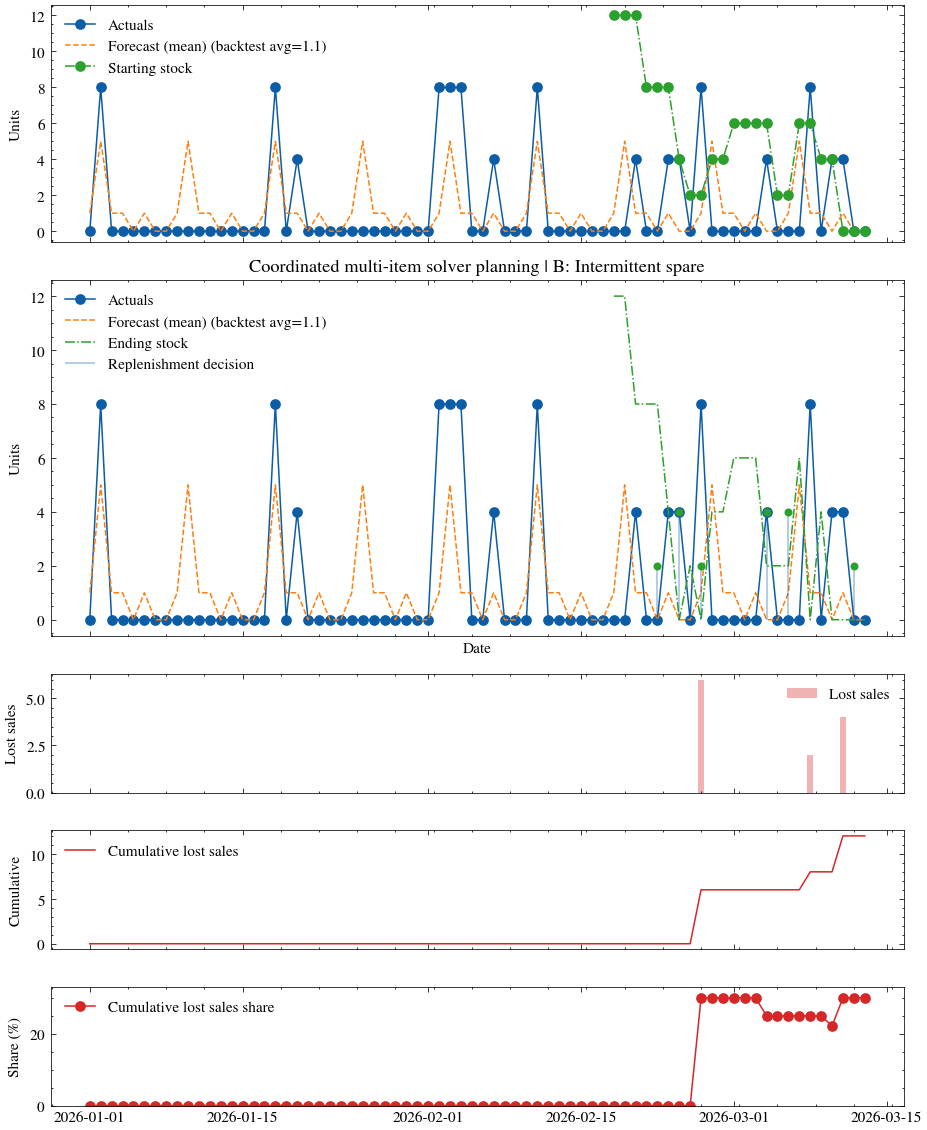

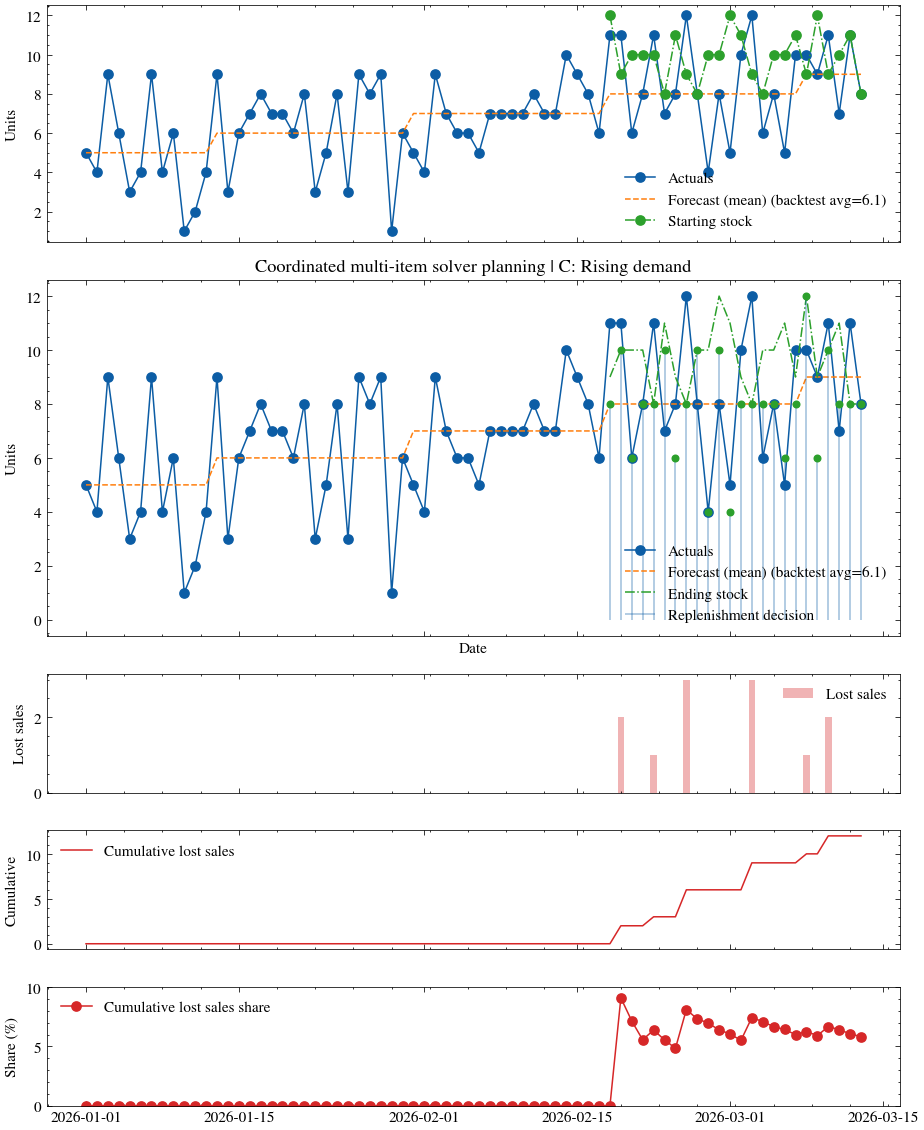

In [8]:
example_ids=sorted(decision_df["unique_id"].unique())[:3]
for uid in example_ids:
    ax=plot_replenishment_decisions(df,decision_df,unique_id=uid,
        title=f"{TITLE} | {uid}: {item_parameters[uid]['item']}",decision_style="line")
    figure=ax.figure
    path=PLOT_DIR/f"{METHOD}_standard_{uid}.png"
    figure.savefig(path,dpi=110,bbox_inches="tight")
    display(Image(filename=str(path)))
    plt.close(figure)


## 7. Overall demand and stock situation

Shared ordering resources do not make stock interchangeable between items.
Aggregate fill rate is demand-weighted; the curves sum actual item outcomes.


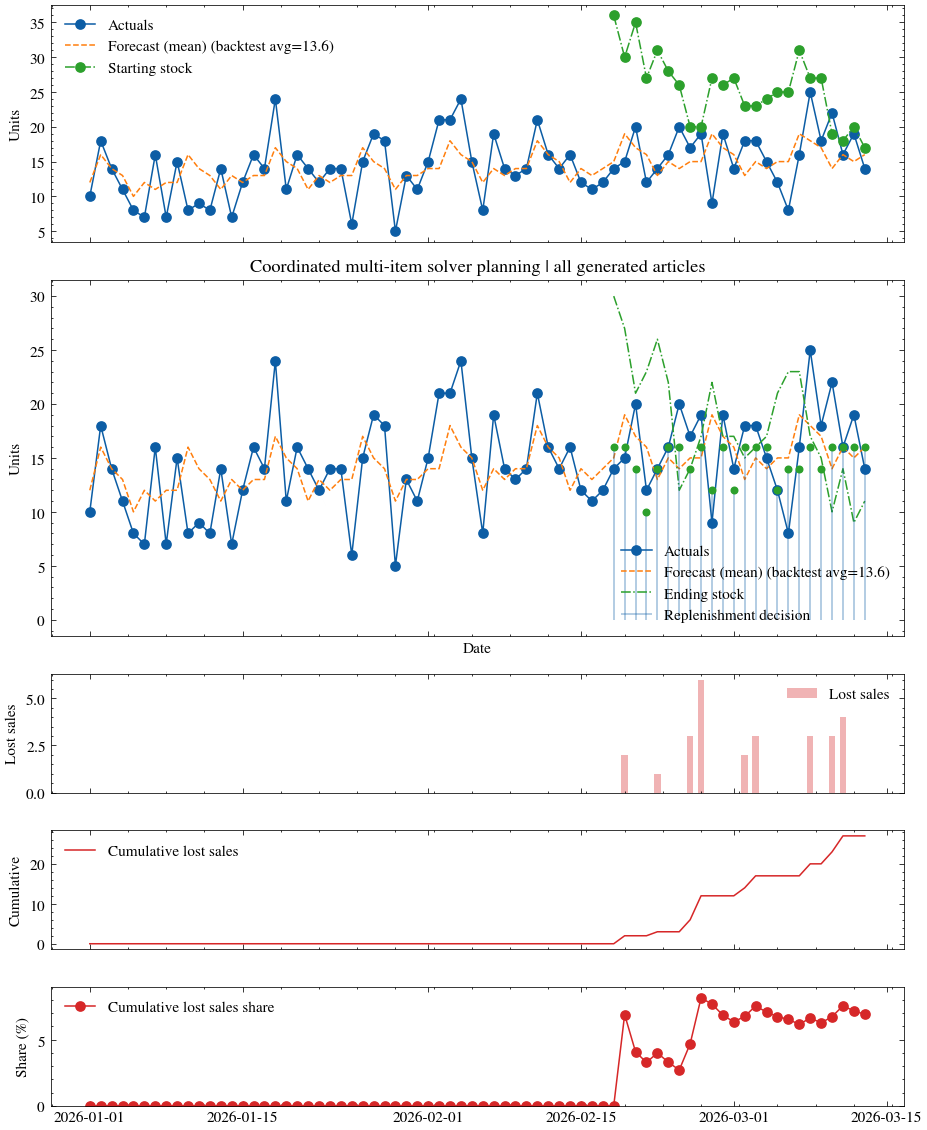

,articles,evaluation_periods,total_demand,fulfilled_units,missed_units,fill_rate,average_total_stock,peak_total_stock,ending_total_stock,ending_pipeline,total_cost
0,3,24,390,363,27,0.9308,18.2917,30,11,16,518.2


,ds,demand,quantity,incoming_stock,starting_stock,ending_stock,on_order,missed_sales,fulfilled_units
0,2026-02-18,14,16,0,36,30,8,0,14
1,2026-02-19,15,16,0,30,27,14,2,13
2,2026-02-20,20,14,8,35,21,14,0,20
3,2026-02-21,12,10,6,27,23,10,0,12
4,2026-02-22,14,14,8,31,26,8,1,13
5,2026-02-23,16,16,2,28,22,12,0,16
6,2026-02-24,20,16,4,26,12,18,0,20
7,2026-02-25,17,14,8,20,14,16,3,14
8,2026-02-26,19,16,6,20,17,16,6,13
9,2026-02-27,9,12,10,27,22,14,0,9


In [9]:
# Sum independently simulated decisions; stock is never pooled between articles.
ax=plot_replenishment_decisions(df,decision_df,aggregate=True,
    title=f"{TITLE} | all generated articles",decision_style="line")
figure=ax.figure
# Reconcile plotted cumulative missed sales with the actual simulation totals.
cumulative_line=next(line for axis in figure.axes for line in axis.lines
                     if line.get_label()=="Cumulative lost sales")
share_line=next(line for axis in figure.axes for line in axis.lines
               if line.get_label()=="Cumulative lost sales share")
total_demand=sum(result.summary.total_demand for result in eval_simulations.values())
total_missed=sum(result.summary.total_lost_sales for result in eval_simulations.values())
assert abs(float(cumulative_line.get_ydata()[-1])-total_missed)<1e-9
assert abs(float(share_line.get_ydata()[-1])-(100*total_missed/total_demand if total_demand else 0))<1e-9
path=PLOT_DIR/f"{METHOD}_standard_aggregate.png"
figure.savefig(path,dpi=110,bbox_inches="tight")
display(Image(filename=str(path)))
plt.close(figure)

overall_daily=decision_df.groupby("ds",as_index=False)[
    ["demand","quantity","incoming_stock","starting_stock","ending_stock","on_order","missed_sales"]
].sum()
overall_daily["fulfilled_units"]=overall_daily.demand-overall_daily.missed_sales
overall_summary_df=pd.DataFrame([dict(articles=len(eval_simulations),evaluation_periods=len(overall_daily),
    total_demand=total_demand,fulfilled_units=total_demand-total_missed,missed_units=total_missed,
    fill_rate=(1-total_missed/total_demand if total_demand else 1),
    average_total_stock=overall_daily.ending_stock.mean(),peak_total_stock=overall_daily.ending_stock.max(),
    ending_total_stock=overall_daily.ending_stock.iloc[-1],ending_pipeline=overall_daily.on_order.iloc[-1],
    total_cost=sum(result.summary.total_cost for result in eval_simulations.values()))])
display(overall_summary_df.round(4))
display(overall_daily.head(12))


## 8. Shared limits and executed resource use

Limits apply per period: 16 ordered units, 6.6 procurement cost, 16 received
units. Budget includes variable purchases plus fixed setup charges. Current
receipts and immediate orders compete for receiving capacity. These are hard
action/receipt limits, not warehouse stock limits or a cumulative budget.


,period,order_units,procurement_cost,receiving_units,received_before_order
0,0,16,6.0,8,0
1,1,16,6.0,10,0
2,2,14,5.4,14,8
3,3,10,4.2,14,6
4,4,14,6.0,16,8
5,5,16,6.0,12,2
6,6,16,6.6,10,4
7,7,14,5.4,16,8
8,8,16,6.6,16,6
9,9,12,4.8,14,10


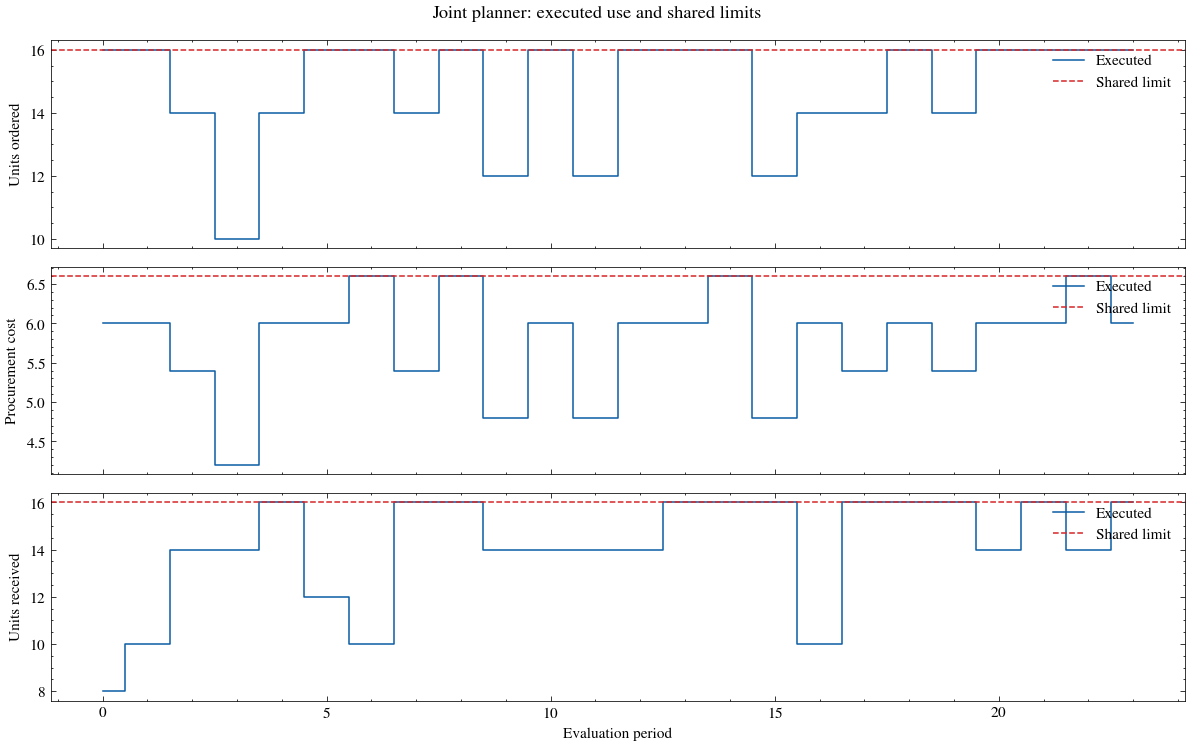

In [10]:
resource_df = pd.DataFrame([asdict(use) for use in coordinated.resource_use])
resource_df["received_before_order"] = [sum(result.snapshots[t].received
    for result in eval_simulations.values()) for t in range(len(resource_df))]
for t,use in enumerate(coordinated.resource_use):
    assert use.order_units == sum(result.snapshots[t].order_placed for result in eval_simulations.values())
    assert use.receiving_units == sum(result.snapshots[t].received + (
        result.snapshots[t].order_placed if items[uid].lead_time == 0 else 0)
        for uid,result in eval_simulations.items())
    assert use.order_units <= limits.max_order_units+1e-9
    assert use.procurement_cost <= limits.procurement_budget+1e-9
    assert use.receiving_units <= limits.max_receiving_units+1e-9
assert abs(resource_df.procurement_cost.sum()-sum(r.summary.ordering_cost for r in eval_simulations.values())) < 1e-7
display(resource_df.head(12))
figure,axes = plt.subplots(3,1,figsize=(11,7),sharex=True)
for ax,column,cap,label in zip(axes,["order_units","procurement_cost","receiving_units"],
    [limits.max_order_units,limits.procurement_budget,limits.max_receiving_units],
    ["Units ordered","Procurement cost","Units received"]):
    ax.step(resource_df.period,resource_df[column],where="mid",label="Executed")
    ax.axhline(cap,color="tab:red",linestyle="--",label="Shared limit")
    ax.set_ylabel(label); ax.legend(loc="upper right")
axes[-1].set_xlabel("Evaluation period")
figure.suptitle("Joint planner: executed use and shared limits")
figure.tight_layout()
path = PLOT_DIR/f"{METHOD}_shared_resources.png"
figure.savefig(path,dpi=110,bbox_inches="tight")
display(Image(filename=str(path)))
plt.close(figure)


## Interpretation and limitations

Compare cost, fill rate, missed units, inventory, order frequency and runtime;
these small examples do not establish policy dominance. The stochastic objective
blends mean and CVaR equally at alpha=.5, giving three tail observations among six
scenarios. The deterministic method minimizes its single forecast-path cost.
Replanning uses only current observations and training-fitted forecasts. A longer
horizon can change decisions; zero terminal value can encourage horizon depletion.
Solver errors, infeasibility or solve limits raise rather than returning an
unchecked action. See [the formulation/API guide](../docs/solver_policies.md).
